# 02 · Curvas de entrenamiento y control del sobreajuste

Rúbrica D2. Mecanismos: **early stopping** sobre F1 macro de validación (paciencia 4), **weight decay** (AdamW), **label smoothing 0.1**, **aumento de datos** y **lr coseno**.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
runs = {p.name: pd.read_csv(p / "history.csv") for p in sorted(RUNS_DIR.iterdir()) if (p / "history.csv").exists()}
infos = {k: json.load(open(RUNS_DIR / k / "train_info.json")) for k in runs if (RUNS_DIR / k / "train_info.json").exists()}
list(runs)

['efficientnet_b0', 'mobilenet_v3_large']

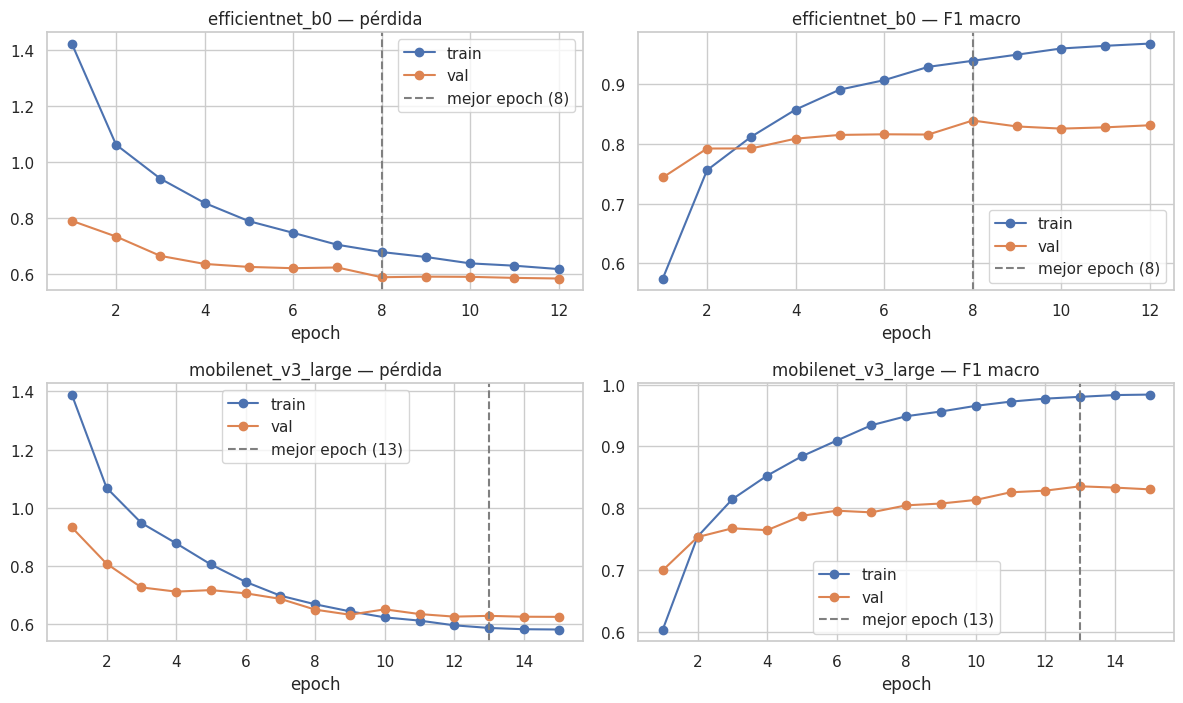

In [3]:
fig, axes = plt.subplots(len(runs), 2, figsize=(12, 3.6 * len(runs)), squeeze=False)
for i, (name, h) in enumerate(runs.items()):
    best = infos.get(name, {}).get("best_epoch")
    axes[i, 0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[i, 0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[i, 0].set_title(f"{name} — pérdida"); axes[i, 0].set_xlabel("epoch")
    axes[i, 1].plot(h.epoch, h.train_f1_macro, "o-", label="train"); axes[i, 1].plot(h.epoch, h.val_f1_macro, "o-", label="val")
    axes[i, 1].set_title(f"{name} — F1 macro"); axes[i, 1].set_xlabel("epoch")
    for a in axes[i]:
        if best: a.axvline(best, color="gray", ls="--", label=f"mejor epoch ({best})")
        a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "curvas_entrenamiento.png", dpi=120); plt.show()

In [4]:
pd.DataFrame({k: {"epochs corridos": v["epochs_run"], "mejor epoch": v["best_epoch"],
                  "F1 val": round(v["best_val_f1_macro"], 4), "minutos": round(v["train_minutes"], 1),
                  "parámetros (M)": round(v["params"] / 1e6, 2)} for k, v in infos.items()}).T

,epochs corridos,mejor epoch,F1 val,minutos,parámetros (M)
efficientnet_b0,12.0,8.0,0.8393,12.9,4.02
mobilenet_v3_large,15.0,13.0,0.8353,15.3,4.21


**Lectura:** la pérdida de *train* incluye label smoothing y aumento de datos, por eso no es directamente comparable con la de validación. El punto de interés es la brecha en F1 macro y el epoch en que la validación deja de mejorar: ahí se guardan los pesos (`best.pt`).